---
## ***Notebook 4: Model Building & Evaluation***
---

# Machine Learning Model Development

## Objective

The objective of this notebook is to build a machine learning classification model capable of predicting the job role of a job posting based on features extracted during web scraping and preprocessing.

Unlike regression, this is a **multi-class classification** problem because the target variable contains multiple job roles such as Data Analyst, Data Scientist, Data Engineer, Machine Learning Engineer, AI Engineer, and Business Analyst.

The notebook follows a complete machine learning pipeline including data preparation, preprocessing, model training, evaluation, comparison, hyperparameter tuning, and model saving.

In [1]:
# Import Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    LabelEncoder
)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
import joblib

In [2]:
df = pd.read_csv("cleaned_naukri_jobs.csv")

df.head()

,Role Searched,Job Title,Company,Rating,Reviews,Experience,Salary,Location,Description,Skills,...,Max Experience,Average Experience,Min Salary,Max Salary,Average Salary,Posted Days,Experience Level,Salary Category,Skill Count,Primary Location
0,Data Analyst,Climate Data Analyst,MSCI Services,3.6,392.0,0-4 Yrs,Not Disclosed,Pune,The Climate Data and Content team is responsib...,"data operations, data analysis, data analysis,...",...,4.0,2.0,NaN,NaN,NaN,21.0,Entry,NaN,8.0,Pune
1,Data Analyst,Data Analyst,Snapdeal,3.6,673.0,1-6 Yrs,Not Disclosed,Gurugram,Providing technical expertise in data storage ...,"master data, python, metadata, data analysis, ...",...,6.0,3.5,NaN,NaN,NaN,21.0,Junior,NaN,8.0,Gurugram
2,Data Analyst,Data Analyst,Cognizant,3.7,63144.0,5-10 Yrs,Not Disclosed,Hyderabad,Role: Data AnalystExperience: 5+ years Preferr...,"data analysis, data visualization, advanced ex...",...,10.0,7.5,NaN,NaN,NaN,7.0,Mid,NaN,8.0,Hyderabad
3,Data Analyst,Data Analyst,MNC,NaN,NaN,0-2 Yrs,2.25-3.5 Lacs PA,"Pimpri-Chinchwad, Pune",We are looking for a motivated and detail-orie...,"google sheets, power bi, ms office, data analy...",...,2.0,1.0,2.25,3.5,2.875,2.0,Entry,Low,8.0,Pimpri-Chinchwad
4,Data Analyst,Data Analyst (English Required),Peroptyx,3.2,17.0,0-5 Yrs,Not Disclosed,Remote,"For thousands of years, maps have provided hum...","data analysis, english, data analysis, data ma...",...,5.0,2.5,NaN,NaN,NaN,14.0,Junior,NaN,8.0,Remote


In [3]:
# Dataset Overview
print("="*60)
print("Dataset Shape")
print("="*60)

print(df.shape)

print("\nDataset Information\n")

df.info()

print("\nMissing Values\n")

display(df.isnull().sum())

Dataset Shape
(4136, 23)

Dataset Information

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4136 entries, 0 to 4135
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Role Searched       4136 non-null   object 
 1   Job Title           4136 non-null   object 
 2   Company             4136 non-null   object 
 3   Rating              3177 non-null   float64
 4   Reviews             3177 non-null   float64
 5   Experience          4084 non-null   object 
 6   Salary              4136 non-null   object 
 7   Location            4114 non-null   object 
 8   Description         4106 non-null   object 
 9   Skills              4103 non-null   object 
 10  Posted              4136 non-null   object 
 11  Job Link            4136 non-null   object 
 12  Min Experience      4084 non-null   float64
 13  Max Experience      4078 non-null   float64
 14  Average Experience  4078 non-null   float64
 15  Min Sala

Role Searched            0
Job Title                0
Company                  0
Rating                 959
Reviews                959
Experience              52
Salary                   0
Location                22
Description             30
Skills                  33
Posted                   0
Job Link                 0
Min Experience          52
Max Experience          58
Average Experience      58
Min Salary            3666
Max Salary            3673
Average Salary        3673
Posted Days              4
Experience Level        58
Salary Category       3673
Skill Count             33
Primary Location        22
dtype: int64

## Problem Formulation

The target variable for this project is **Role Searched**.

Since the target contains multiple categories representing different job roles, the problem is formulated as a **multi-class classification** task.

The model will learn relationships between job characteristics and predict the most likely job role for unseen job postings.

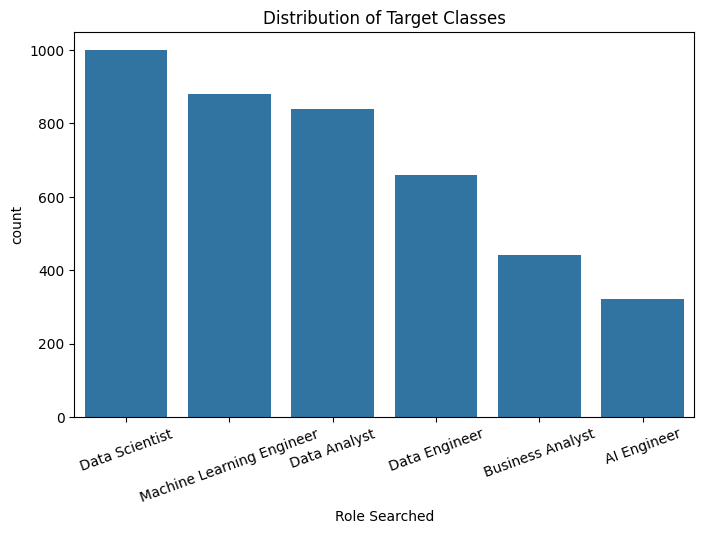

In [4]:
# Target Variable Analysis
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Role Searched",
    order=df["Role Searched"].value_counts().index
)

plt.xticks(rotation=20)
plt.title("Distribution of Target Classes")
plt.show()

In [5]:
# Feature Selection
features = [
    "Primary Location",
    "Average Experience",
    "Rating",
    "Reviews",
    "Skill Count",
    "Posted Days",
    "Skills"
]

target = "Role Searched"

In [6]:
X = df[features].copy()
y = df[target]

In [7]:
# Encoding Target Variable
label_encoder = LabelEncoder()
label_encoder.fit(df["Role Searched"])
y = label_encoder.transform(df["Role Searched"])

In [8]:
pd.DataFrame({
    "Encoded": range(len(label_encoder.classes_)),
    "Role": label_encoder.classes_
})

,Encoded,Role
0,0,AI Engineer
1,1,Business Analyst
2,2,Data Analyst
3,3,Data Engineer
4,4,Data Scientist
5,5,Machine Learning Engineer


In [9]:
# Train_Test_Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

## Data Preprocessing

The dataset contains three different types of features:

- Numerical Features
- Categorical Features
- Text Features

Each type requires a different preprocessing technique before training the machine learning model.

- Numerical features are imputed using the median.
- Categorical features are transformed using One-Hot Encoding.
- Text features (Skills) are converted into numerical vectors using TF-IDF Vectorization.

In [14]:
numeric_features = [
    "Average Experience",
    "Rating",
    "Reviews",
    "Skill Count",
    "Posted Days"
]

categorical_features = [
    "Primary Location"
]

In [15]:
# Build PreProcessing pipelines
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

# Number Pipeline
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])
# Categorical Pipeline
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numeric_transformer,
            numeric_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ],
    remainder="drop"
)

In [17]:
# PreProcess Numeric + Categorical Features
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [30]:
# TF-IDF on Skills
from sklearn.feature_extraction.text import TfidfVectorizer

# TF-IDF on Skills
tfidf = TfidfVectorizer(
    max_features=500,
    ngram_range=(1, 2),
    min_df=2,
    stop_words="english"
)

X_train_skills = tfidf.fit_transform(
    X_train["Skills"].fillna("")
)

X_test_skills = tfidf.transform(
    X_test["Skills"].fillna("")
)

In [31]:
# Combine Both Feature Sets
from scipy.sparse import hstack
X_train_final = hstack([
    X_train_processed,
    X_train_skills
])

X_test_final = hstack([
    X_test_processed,
    X_test_skills
])

In [32]:
# Checking Dimensions
print("Training Shape :", X_train_final.shape)
print("Testing Shape  :", X_test_final.shape)

Training Shape : (3308, 676)
Testing Shape  : (828, 676)


In [33]:
# Define Models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=10000,
        solver="saga",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=20,
        min_samples_split=5,
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        max_depth=25,
        min_samples_split=2,
        random_state=42,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=500,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="multi:softprob",
        eval_metric="mlogloss",
        random_state=42
    )
}

In [34]:
# Train All Models
results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_final, y_train)
    y_pred = model.predict(X_test_final)
    trained_models[name] = model
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_test,
        y_pred,
        average="weighted",
        zero_division=0
    )
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...
Training XGBoost...


In [35]:
results = pd.DataFrame(results)

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.310386,0.147230,0.310386,0.185471
1,Decision Tree,0.596618,0.606636,0.596618,0.600413
2,Random Forest,0.647343,0.660013,0.647343,0.648588
3,Gradient Boosting,0.618357,0.635866,0.618357,0.624230
4,XGBoost,0.652174,0.665271,0.652174,0.656106


In [36]:
results.sort_values(
    "Accuracy",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1 Score
4,XGBoost,0.652174,0.665271,0.652174,0.656106
2,Random Forest,0.647343,0.660013,0.647343,0.648588
3,Gradient Boosting,0.618357,0.635866,0.618357,0.624230
1,Decision Tree,0.596618,0.606636,0.596618,0.600413
0,Logistic Regression,0.310386,0.147230,0.310386,0.185471


In [37]:
best_model_name = results.sort_values(
    by="Accuracy",
    ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_model_name]

print(best_model_name)

XGBoost


In [38]:
y_pred = best_model.predict(X_test_final)

print(classification_report(
    y_test,
    y_pred,
    target_names=label_encoder.classes_.astype(str)
))

                           precision    recall  f1-score   support

              AI Engineer       0.70      0.47      0.56        64
         Business Analyst       0.95      0.84      0.89        88
             Data Analyst       0.83      0.83      0.83       168
            Data Engineer       0.91      0.89      0.90       132
           Data Scientist       0.48      0.54      0.51       200
Machine Learning Engineer       0.39      0.40      0.40       176

                 accuracy                           0.65       828
                macro avg       0.71      0.66      0.68       828
             weighted avg       0.67      0.65      0.66       828



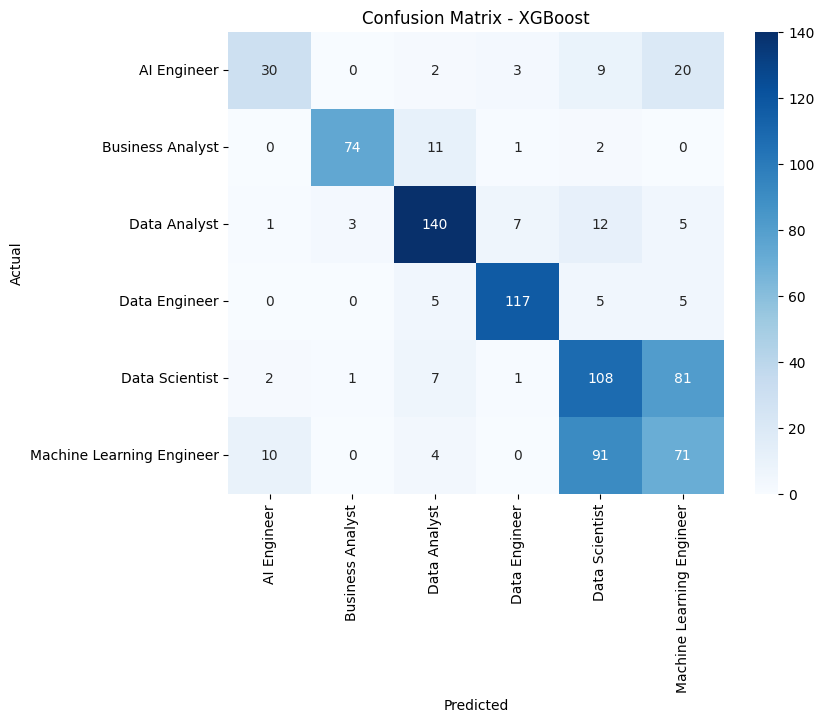

In [39]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_model_name}")

plt.show()

In [40]:
scores = cross_val_score(
    best_model,
    X_train_final,
    y_train,
    cv=5,
    scoring="accuracy"
)

print("Cross Validation Scores:")
print(scores)

print(f"\nAverage Accuracy: {scores.mean():.4f}")
print(f"Standard Deviation: {scores.std():.4f}")

Cross Validation Scores:
[0.64954683 0.68126888 0.68277946 0.67170953 0.67019667]

Average Accuracy: 0.6711
Standard Deviation: 0.0119


In [41]:
# Prediction vs Actual
prediction_df = pd.DataFrame({
    "Actual": label_encoder.inverse_transform(y_test),
    "Predicted": label_encoder.inverse_transform(y_pred)
})

prediction_df["Correct"] = (
    prediction_df["Actual"] == prediction_df["Predicted"]
)

prediction_df.head(20)

,Actual,Predicted,Correct
0,Machine Learning Engineer,Machine Learning Engineer,True
1,Data Scientist,Data Scientist,True
2,Data Analyst,Data Analyst,True
3,Machine Learning Engineer,Machine Learning Engineer,True
4,Data Analyst,Data Analyst,True
5,Data Engineer,Data Engineer,True
6,Data Engineer,Data Engineer,True
7,Machine Learning Engineer,Machine Learning Engineer,True
8,Business Analyst,Business Analyst,True
9,Data Scientist,Machine Learning Engineer,False
